In [1]:
import glob
import os
import zipfile
import pandas as pd

# 1. Extract the dataset archive
with zipfile.ZipFile("/content/cyicle (2).zip", "r") as zip_ref:
    zip_ref.extractall("cycicle_extracted")

print("Dataset extracted successfully.")

# 2. Define data path and locate all monthly CSV files
path = "cycicle_extracted"
all_files = glob.glob(os.path.join(path, "*.csv"))

# Fallback: recursive search if files are located inside subdirectories
if not all_files:
    all_files = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)

# 3. Read and concatenate all CSV files into a single DataFrame
df_list = [pd.read_csv(f) for f in all_files]
cyclistic_df = pd.concat(df_list, ignore_index=True)

# 4. Convert timestamp columns to datetime objects
cyclistic_df["started_at"] = pd.to_datetime(cyclistic_df["started_at"])
cyclistic_df["ended_at"] = pd.to_datetime(cyclistic_df["ended_at"])

# Engineer new features: ride duration in seconds and day of the week
cyclistic_df["ride_length"] = (
    cyclistic_df["ended_at"] - cyclistic_df["started_at"]
).dt.total_seconds()

cyclistic_df["day_of_week"] = cyclistic_df["started_at"].dt.dayofweek + 1

# 5. Data cleaning: filter out invalid/negative ride lengths and drop missing key attributes
cyclistic_df = cyclistic_df[cyclistic_df["ride_length"] > 0]
cyclistic_df = cyclistic_df.dropna(
    subset=["ride_id", "rideable_type", "started_at", "ended_at", "member_casual"]
)

print(
    "Data processing and cleaning completed successfully. Total rows:",
    len(cyclistic_df),
)
print(cyclistic_df.head(3))

Dataset extracted successfully.
Data processing and cleaning completed successfully. Total rows: 6171756
            ride_id rideable_type              started_at  \
0  AAED255E1310E516  classic_bike 2025-10-27 08:19:53.208   
1  F90C86BF3BB85040  classic_bike 2025-10-14 07:42:55.465   
2  90429D9729A3EE8E  classic_bike 2025-10-12 08:18:23.613   

                 ended_at           start_station_name start_station_id  \
0 2025-10-27 08:25:53.481           Wells St & Polk St         CHI00606   
1 2025-10-14 08:04:08.663  Racine Ave & Wrightwood Ave         CHI00506   
2 2025-10-12 08:28:38.983         Clinton St & 18th St         CHI00235   

               end_station_name end_station_id  start_lat  start_lng  \
0   Franklin St & Washington St       CHI02074  41.872732 -87.633516   
1          McClurg Ct & Ohio St       CHI00330  41.928887 -87.658971   
2  Desplaines St & Jackson Blvd       CHI00518  41.857950 -87.640826   

     end_lat    end_lng member_casual  ride_length  day_of_w

In [2]:
# Export the combined and cleaned DataFrame to a new CSV file
cyclistic_df.to_csv("Cyclistic_Combined_Cleaned.csv", index=False)

print("Cleaned dataset successfully saved as: Cyclistic_Combined_Cleaned.csv")

Cleaned dataset successfully saved as: Cyclistic_Combined_Cleaned.csv


In [3]:
# 1. Calculate descriptive statistics for ride duration (count, mean, max, min) grouped by user type
summary_stats = cyclistic_df.groupby('member_casual')['ride_length'].agg(['count', 'mean', 'max', 'min'])
print("--- Ride Duration Statistics (in Seconds) ---")
print(summary_stats)

# 2. Calculate the average ride duration for each day of the week categorized by user type
avg_ride_by_day = cyclistic_df.groupby(['member_casual', 'day_of_week'])['ride_length'].mean().unstack()
print("\n--- Average Ride Duration by Day of the Week ---")
print(avg_ride_by_day)

# 3. Calculate total ride counts per day of the week by user type (for peak usage identification)
ride_count_by_day = cyclistic_df.groupby(['member_casual', 'day_of_week'])['ride_id'].count().unstack()
print("\n--- Total Ride Count by Day of the Week ---")
print(ride_count_by_day)

--- Ride Duration Statistics (in Seconds) ---
                 count         mean        max    min
member_casual                                        
casual         2189015  1225.151983  93597.011  0.070
member         3982741   740.455260  93594.221  0.056

--- Average Ride Duration by Day of the Week ---
day_of_week              1            2            3            4  \
member_casual                                                       
casual         1220.121624  1062.009124  1021.911150  1082.145562   
member          723.012489   711.378477   706.762607   713.642306   

day_of_week              5            6            7  
member_casual                                         
casual         1200.491188  1377.234875  1425.830306  
member          737.426202   817.564023   810.909699  

--- Total Ride Count by Day of the Week ---
day_of_week         1       2       3       4       5       6       7
member_casual                                                        
casual

/tmp/ipykernel_3488/4288902341.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(


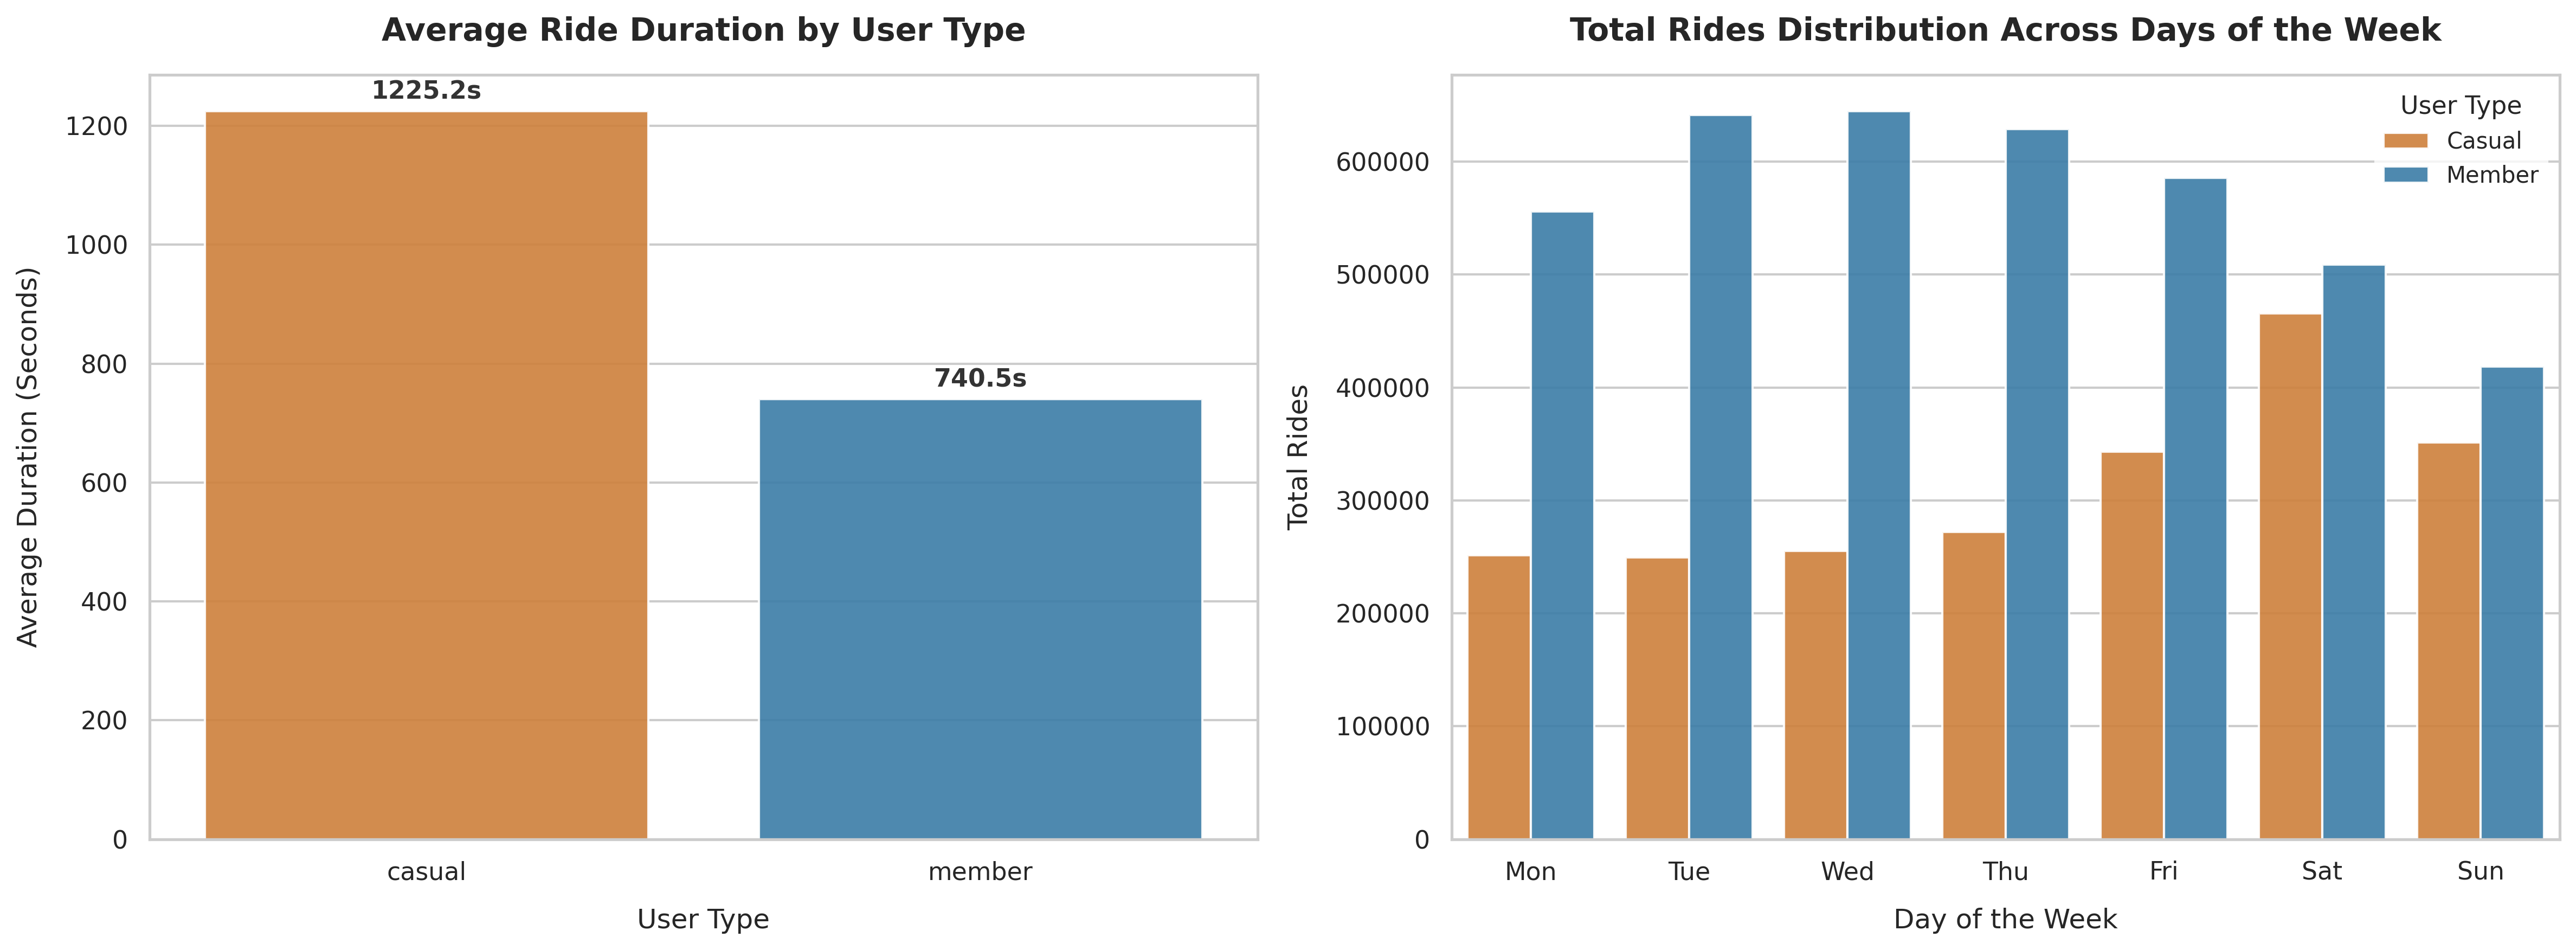

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set overall visualization style and theme
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=300)

# Define custom professional color palette for user types
palette = {"casual": "#E67E22", "member": "#2980B9"}

# --- 1. First Plot: Average Ride Duration by User Type ---
avg_duration = (
    cyclistic_df.groupby("member_casual")["ride_length"].mean().reset_index()
)

ax1 = sns.barplot(
    data=avg_duration,
    x="member_casual",
    y="ride_length",
    palette=palette,
    ax=axes[0],
    alpha=0.9,
)
axes[0].set_title(
    "Average Ride Duration by User Type", fontsize=14, fontweight="bold", pad=15
)
axes[0].set_xlabel("User Type", fontsize=12, labelpad=10)
axes[0].set_ylabel("Average Duration (Seconds)", fontsize=12, labelpad=10)

# Annotate bars with data labels
for p in ax1.patches:
    height = p.get_height()
    ax1.annotate(
        f"{height:.1f}s",
        (p.get_x() + p.get_width() / 2.0, height),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color="#333333",
        xytext=(0, 3),
        textcoords="offset points",
    )

# --- 2. Second Plot: Total Rides Distribution Across Days of the Week ---
day_order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
day_names_map = {
    1: "Mon",
    2: "Tue",
    3: "Wed",
    4: "Thu",
    5: "Fri",
    6: "Sat",
    7: "Sun",
}
cyclistic_df["day_name"] = cyclistic_df["day_of_week"].map(day_names_map)

weekly_trend = (
    cyclistic_df.groupby(["day_name", "member_casual"])["ride_id"]
    .count()
    .reset_index()
)

ax2 = sns.barplot(
    data=weekly_trend,
    x="day_name",
    y="ride_id",
    hue="member_casual",
    order=day_order,
    palette=palette,
    ax=axes[1],
    alpha=0.9,
)
axes[1].set_title(
    "Total Rides Distribution Across Days of the Week",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
axes[1].set_xlabel("Day of the Week", fontsize=12, labelpad=10)
axes[1].set_ylabel("Total Rides", fontsize=12, labelpad=10)

# Customize legend properties and layout
handles, labels = ax2.get_legend_handles_labels()
ax2.legend(
    handles=handles,
    labels=["Casual", "Member"],
    title="User Type",
    title_fontsize="11",
    fontsize="10",
    frameon=True,
    facecolor="white",
    edgecolor="none",
)

# Adjust layout spacing and save the high-resolution figure
plt.tight_layout()
plt.savefig(
    "cyclistic_professional_report_charts.png", dpi=300, bbox_inches="tight"
)
plt.show()

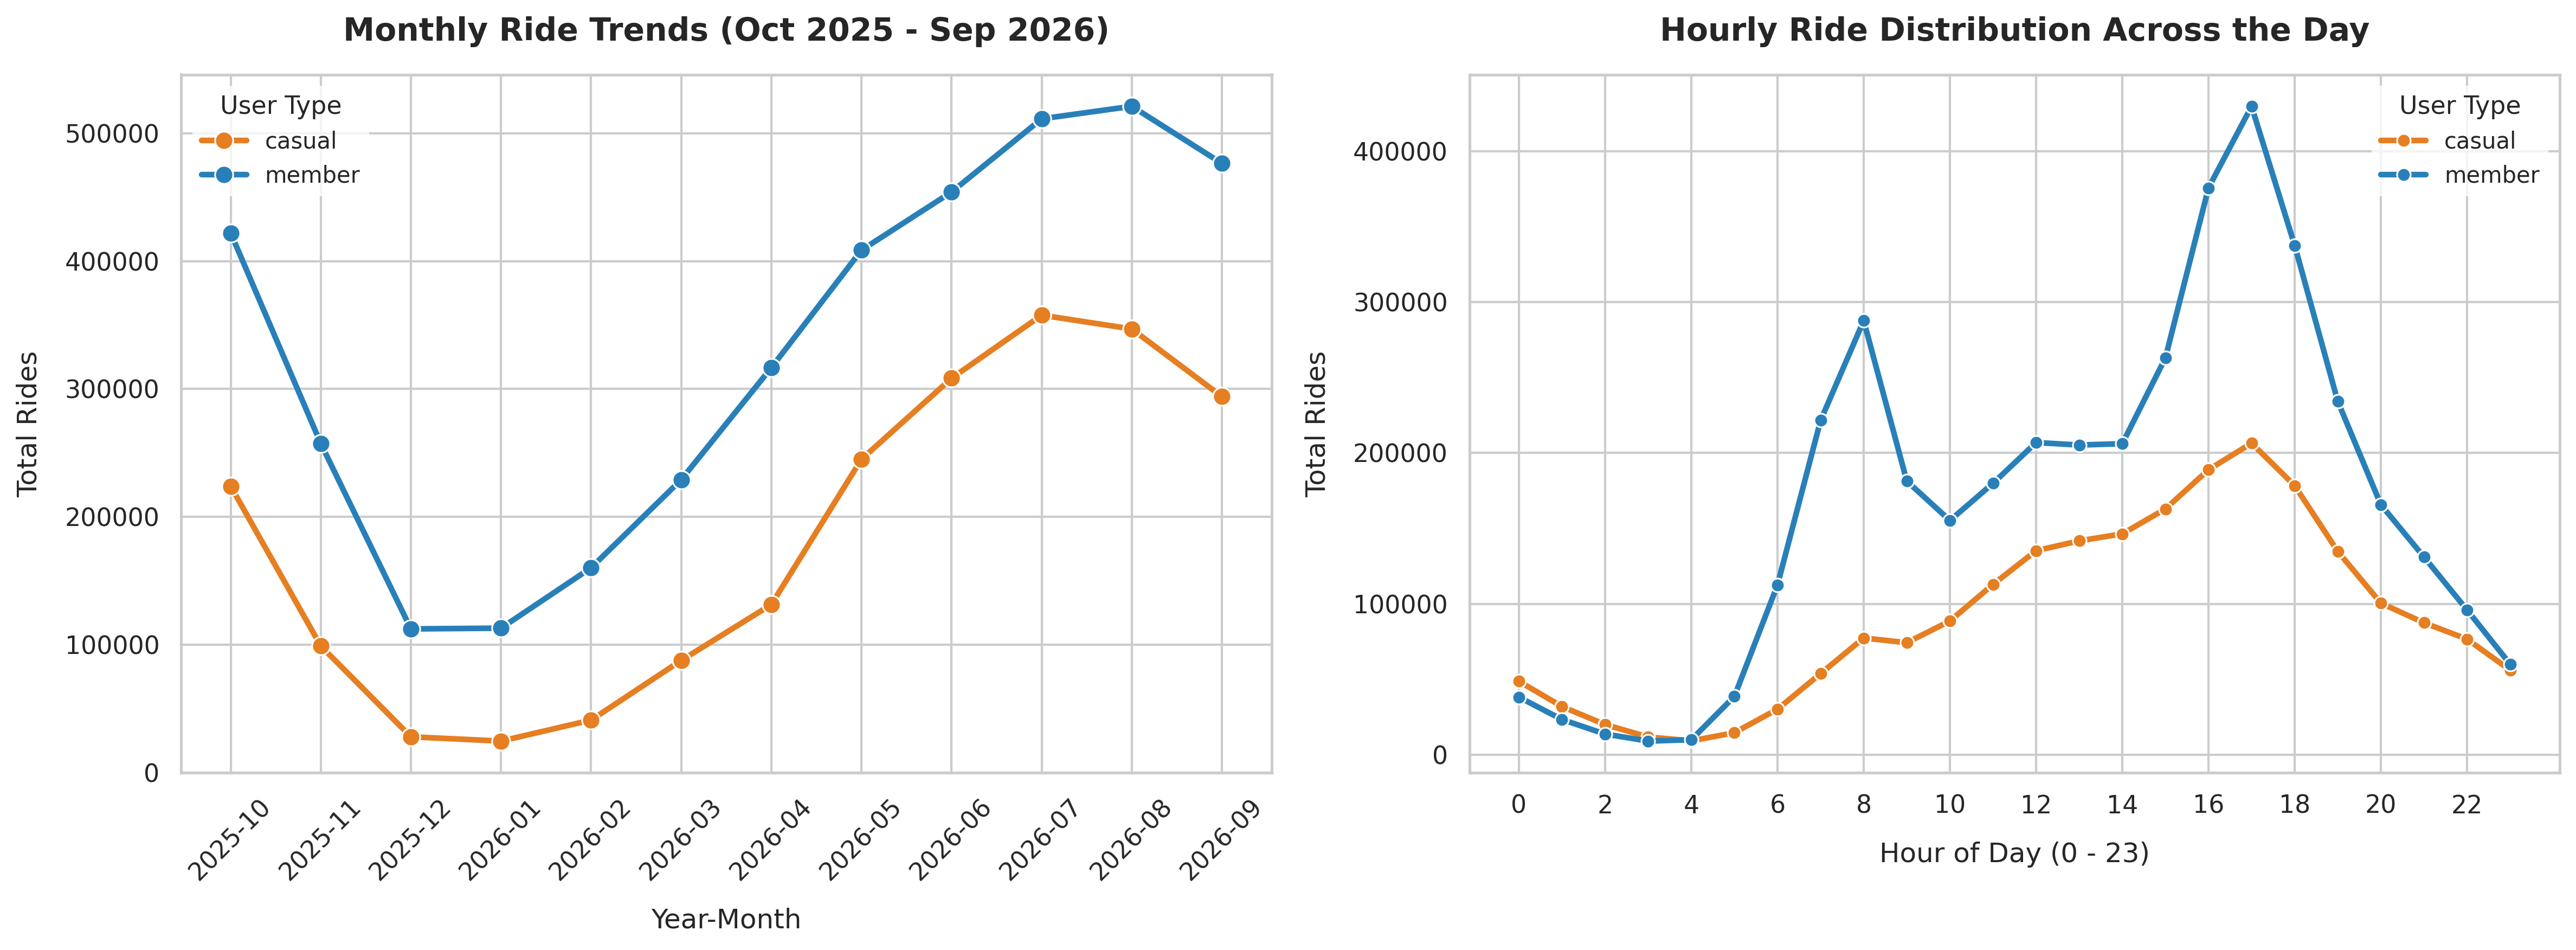

In [5]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Set overall visualization style and theme
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=300)
palette = {"casual": "#E67E22", "member": "#2980B9"}

# Ensure datetime conversion and extract year-month period
cyclistic_df["started_at"] = pd.to_datetime(cyclistic_df["started_at"])
cyclistic_df["year_month"] = (
    cyclistic_df["started_at"].dt.to_period("M").astype(str)
)

# --- 1. First Plot: Monthly Ride Trends (Filtered for Oct 2025 - Sep 2026) ---
filtered_monthly = cyclistic_df[cyclistic_df["year_month"] >= "2025-10"]

monthly_trend = (
    filtered_monthly.groupby(["year_month", "member_casual"])["ride_id"]
    .count()
    .reset_index()
)

sns.lineplot(
    data=monthly_trend,
    x="year_month",
    y="ride_id",
    hue="member_casual",
    palette=palette,
    marker="o",
    linewidth=2.5,
    markersize=8,
    ax=axes[0],
)

axes[0].set_title(
    "Monthly Ride Trends (Oct 2025 - Sep 2026)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
axes[0].set_xlabel("Year-Month", fontsize=12, labelpad=10)
axes[0].set_ylabel("Total Rides", fontsize=12, labelpad=10)
axes[0].tick_params(axis="x", rotation=45)

axes[0].legend(
    title="User Type",
    title_fontsize="11",
    fontsize="10",
    frameon=True,
    facecolor="white",
    edgecolor="none",
)

# --- 2. Second Plot: Hourly Ride Distribution (Peak Hours Analysis) ---
cyclistic_df["hour"] = cyclistic_df["started_at"].dt.hour
hourly_trend = (
    cyclistic_df.groupby(["hour", "member_casual"])["ride_id"]
    .count()
    .reset_index()
)

sns.lineplot(
    data=hourly_trend,
    x="hour",
    y="ride_id",
    hue="member_casual",
    palette=palette,
    marker="o",
    linewidth=2.5,
    markersize=6,
    ax=axes[1],
)

axes[1].set_title(
    "Hourly Ride Distribution Across the Day",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
axes[1].set_xlabel("Hour of Day (0 - 23)", fontsize=12, labelpad=10)
axes[1].set_ylabel("Total Rides", fontsize=12, labelpad=10)
axes[1].set_xticks(range(0, 24, 2))

axes[1].legend(
    title="User Type",
    title_fontsize="11",
    fontsize="10",
    frameon=True,
    facecolor="white",
    edgecolor="none",
)

# Adjust layout spacing and save the high-resolution figure
plt.tight_layout()
plt.savefig(
    "cyclistic_monthly_hourly_clean.png", dpi=300, bbox_inches="tight"
)
plt.show()